# Open Ended Problem 06 – Morphological Removal of Bright Specks and Dark Cracks
**Subject:** Digital Signal and Image Processing (01CT1513)  |  **Enrolment No:** 92400133147  
**Department of Information and Communication Technology, Faculty of Engineering & Technology, Marwadi University**

**Aim:** To remove small bright specks and fill narrow dark cracks in digital images using morphological operations
(opening and closing) while preserving the overall shape and important details of the objects.

**Pipeline:** load → grayscale → binary (Otsu) → structuring elements → opening → closing → grayscale top-hat / black-hat → compare → save.

## 1. Import Required Libraries
OpenCV performs the morphological operations, NumPy handles the image arrays, and Matplotlib displays the original and processed images.

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
plt.rcParams["image.cmap"] = "gray"
print("OpenCV version :", cv2.__version__)
print("NumPy version  :", np.__version__)

OpenCV version : 4.12.0
NumPy version  : 2.1.3


## 2. Define Image Folder and Load Images
The three input images are loaded from the folder `images/` (use your own files: `image1_object.png`, `image2_photo.png`, `image3_fingerprint.png`).

> **Note:** if the files are not found, the cell below automatically generates three *stand-in test images*
> (a blob-shaped object, an old scratched photograph and a fingerprint-like ridge pattern) so that the notebook always runs end-to-end.
> Replace them with your real images to get your own results – no other change is needed.

In [5]:
IMAGE_DIR  = r"C:\Users\admin\Documents\DSIP\Lab Experiment"
OUTPUT_DIR = r"C:\Users\admin\Documents\DSIP\Lab Experiment\output"
os.makedirs(IMAGE_DIR,  exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

FILES = {
    "Image 1 - Binary Object": "OPE-6.1.jpg",
    "Image 2 - Photograph"   : "OPE-6.2.jpg",
    "Image 3 - Fingerprint"  : "OPE-6.3.jpg",
}

# ---------- stand-in image generators (used only when real files are missing) ----------
def make_object(h=400, w=400, seed=1):
    rng = np.random.default_rng(seed)
    img = np.full((h, w), 235, np.uint8)                       # light background
    cv2.ellipse(img, (200, 210), (130, 95), 20, 0, 360, 30, -1)  # large dark object
    cv2.rectangle(img, (150, 80), (250, 140), 30, -1)
    cv2.circle(img, (110, 300), 45, 30, -1)
    for _ in range(140):                                         # small dark specks on background
        x, y = rng.integers(5, w-5), rng.integers(5, h-5)
        if img[y, x] > 200: img[y:y+int(rng.integers(1, 3)), x:x+int(rng.integers(1, 3))] = 20
    for _ in range(90):                                          # small bright holes inside object
        x, y = rng.integers(60, w-60), rng.integers(60, h-60)
        if img[y, x] < 60: cv2.circle(img, (x, y), int(rng.integers(0, 2)), 240, -1)
    for _ in range(6):                                           # narrow bright cracks inside object
        x, y = rng.integers(120, 280), rng.integers(150, 280)
        cv2.line(img, (x, y), (x + int(rng.integers(-18, 18)), y + int(rng.integers(8, 22))), 240, 1)
    return img

def make_photo(h=400, w=400, seed=2):
    rng = np.random.default_rng(seed)
    yy, xx = np.mgrid[0:h, 0:w]
    img = 90 + 70*np.exp(-(((xx-200)/150.)**2 + ((yy-170)/170.)**2))      # soft face-like blob
    img += 25*np.sin(xx/37.) * np.cos(yy/43.)
    cv2.circle(img, (200, 160), 70, 170, -1); cv2.ellipse(img, (200, 330), (110, 80), 0, 180, 360, 120, -1)
    img = cv2.GaussianBlur(img.astype(np.float32), (0, 0), 3)
    img += rng.normal(0, 4, img.shape)
    img = np.clip(img, 0, 255).astype(np.uint8)
    for _ in range(220):                                                    # bright dust specks
        cv2.circle(img, (int(rng.integers(0, w)), int(rng.integers(0, h))), int(rng.integers(0, 2)), 250, -1)
    for _ in range(14):                                                     # thin dark scratches
        x, y = int(rng.integers(0, w)), int(rng.integers(0, h-60))
        cv2.line(img, (x, y), (x + int(rng.integers(-15, 15)), y + int(rng.integers(25, 80))), 15, 1)
    return img

def make_fingerprint(h=400, w=400, seed=3):
    rng = np.random.default_rng(seed)
    yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)
    cx, cy = w/2, h/2 + 20
    r  = np.sqrt(((xx-cx)/1.0)**2 + ((yy-cy)/1.25)**2)
    th = np.arctan2(yy-cy, xx-cx)
    ridge = np.sin(r/4.2 + 1.6*np.sin(3*th)*np.exp(-r/120.) + 0.02*r)       # curved ridges
    img = (ridge*0.5 + 0.5)
    mask = (((xx-cx)/170)**2 + ((yy-cy)/190)**2) < 1
    img = np.where(mask, img, 0.0)
    img = (img*255).astype(np.uint8)
    img = cv2.GaussianBlur(img, (3, 3), 0)
    for _ in range(260):                                                    # isolated bright specks
        x, y = int(rng.integers(0, w)), int(rng.integers(0, h))
        img[y, x] = 255
    for _ in range(110):                                                    # narrow dark gaps in ridges
        x, y = int(rng.integers(60, w-60)), int(rng.integers(60, h-60))
        if img[y, x] > 150: img[y:y+2, x] = 0
    return img

GENERATORS = [make_object, make_photo, make_fingerprint]

images = {}
for (title, fname), gen in zip(FILES.items(), GENERATORS):
    path = os.path.join(IMAGE_DIR, fname)
    if not os.path.exists(path):
        cv2.imwrite(path, gen())
        print(f"[info] {path} not found -> stand-in image generated")
    bgr = cv2.imread(path)
    if bgr is None:
        raise FileNotFoundError(path)
    images[title] = bgr
    print(f"Loaded {title:26s} shape={bgr.shape} dtype={bgr.dtype}")

Loaded Image 1 - Binary Object    shape=(370, 408, 3) dtype=uint8
Loaded Image 2 - Photograph       shape=(387, 414, 3) dtype=uint8
Loaded Image 3 - Fingerprint      shape=(393, 620, 3) dtype=uint8


## 3. Display Original Images
Displaying the original images helps identify bright specks, dark cracks, scratches and other unwanted noise before applying morphological operations.

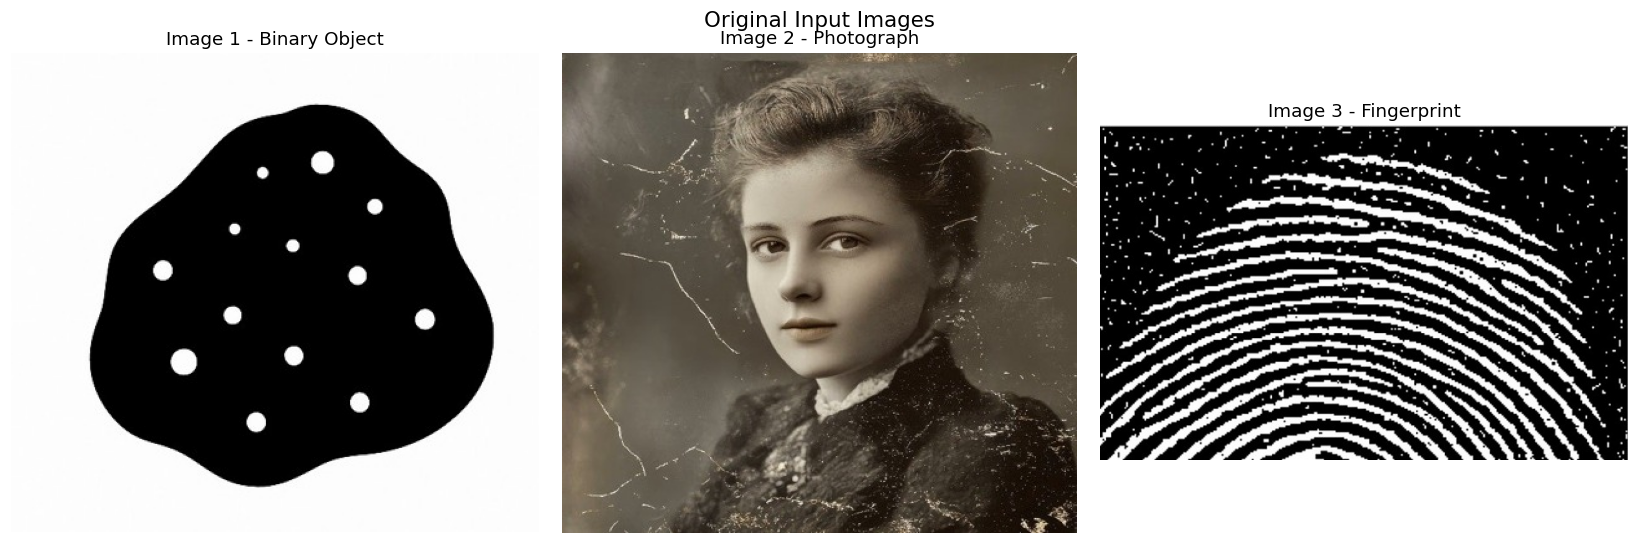

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (title, img) in zip(axes, images.items()):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title); ax.axis("off")
plt.suptitle("Original Input Images", fontsize=14)
plt.tight_layout(); plt.show()

## 4. Convert Images into Grayscale
Grayscale conversion reduces the image to a single intensity channel, making morphological processing easier.

In [8]:
gray = {t: cv2.cvtColor(im, cv2.COLOR_BGR2GRAY) for t, im in images.items()}
g1, g2, g3 = list(gray.values())
for t, g in gray.items():
    print(f"{t:26s} min={g.min():3d} max={g.max():3d} mean={g.mean():6.2f}")

Image 1 - Binary Object    min=  0 max=255 mean=145.42
Image 2 - Photograph       min=  2 max=240 mean= 83.42
Image 3 - Fingerprint      min=  0 max=255 mean= 67.34


## 5. Display Grayscale Images
Grayscale images provide the intensity information that is useful for identifying small bright spots and dark cracks.

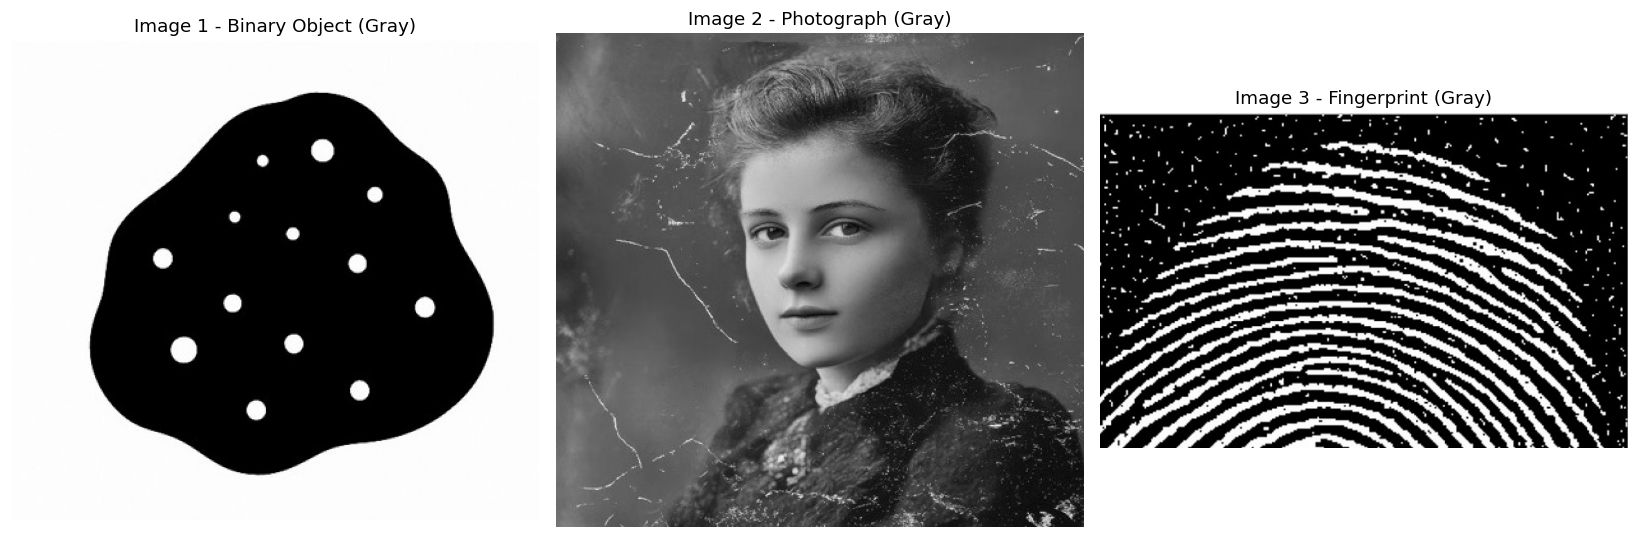

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (title, g) in zip(axes, gray.items()):
    ax.imshow(g, cmap="gray", vmin=0, vmax=255); ax.set_title(title + " (Gray)"); ax.axis("off")
plt.tight_layout(); plt.show()

## 6. Convert Images into Binary Images (Otsu Thresholding)
Otsu's method selects the threshold automatically by maximising the between-class variance of the histogram.
Image 1 has a **dark** object on a light background, so inverse thresholding is used (object → white = 255).
Image 3 has **bright** ridges, so normal thresholding is used. Image 2 is a photograph and is processed in grayscale (Section 11).

In [10]:
# Image 1 : dark foreground -> THRESH_BINARY_INV so that the object becomes white (255)
t1, bin1 = cv2.threshold(g1, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
# Image 3 : bright ridges -> THRESH_BINARY
t3, bin3 = cv2.threshold(g3, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

print(f"Otsu threshold  Image 1 = {t1:.0f}   |   Image 3 = {t3:.0f}")
print("Unique values  Image 1 :", np.unique(bin1), "| Image 3 :", np.unique(bin3))

Otsu threshold  Image 1 = 126   |   Image 3 = 119
Unique values  Image 1 : [  0 255] | Image 3 : [  0 255]


## 7. Display Binary Images
Binary images contain only two pixel values: 0 (black) and 255 (white). Morphological operations are applied to the white foreground.

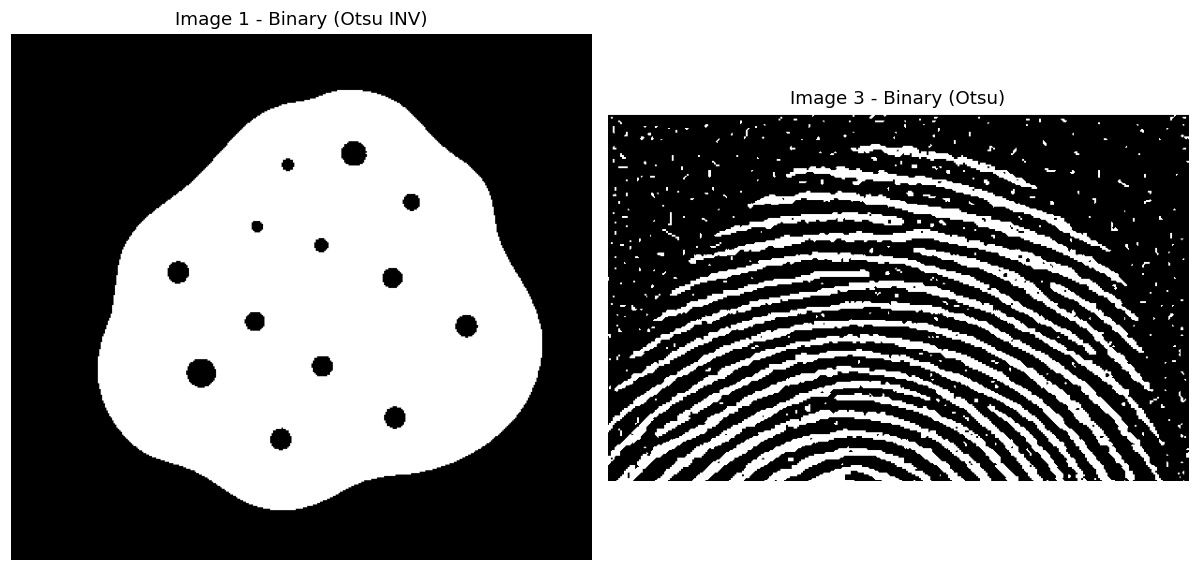

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, im, t in zip(axes, [bin1, bin3], ["Image 1 - Binary (Otsu INV)", "Image 3 - Binary (Otsu)"]):
    ax.imshow(im, cmap="gray"); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()

## 8. Define Structuring Elements
A **3×3 elliptical** kernel is used for removing very small noise, and a **5×5 elliptical** kernel is used for filling slightly larger gaps.
An elliptical shape gives smoother treatment of curved boundaries than a square kernel.

In [12]:
k3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
k5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
print("3x3 elliptical SE:\n", k3, "\n")
print("5x5 elliptical SE:\n", k5)

3x3 elliptical SE:
 [[0 1 0]
 [1 1 1]
 [0 1 0]] 

5x5 elliptical SE:
 [[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


## 9. Apply Morphological Opening
Opening = erosion followed by dilation with the same structuring element: **A ∘ B = (A ⊖ B) ⊕ B**.
It removes small isolated white (foreground) regions while preserving the larger objects.

In [13]:
open1 = cv2.morphologyEx(bin1, cv2.MORPH_OPEN, k3)     # Image 1 : remove small bright specks
open3 = cv2.morphologyEx(bin3, cv2.MORPH_OPEN, k3)     # Image 3 : remove isolated bright specks

# the same operation written explicitly as erosion -> dilation (verification)
open1_manual = cv2.dilate(cv2.erode(bin1, k3), k3)
print("cv2 OPEN == erode->dilate (Image 1):", np.array_equal(open1, open1_manual))

cv2 OPEN == erode->dilate (Image 1): True


## 10. Display Opening Results

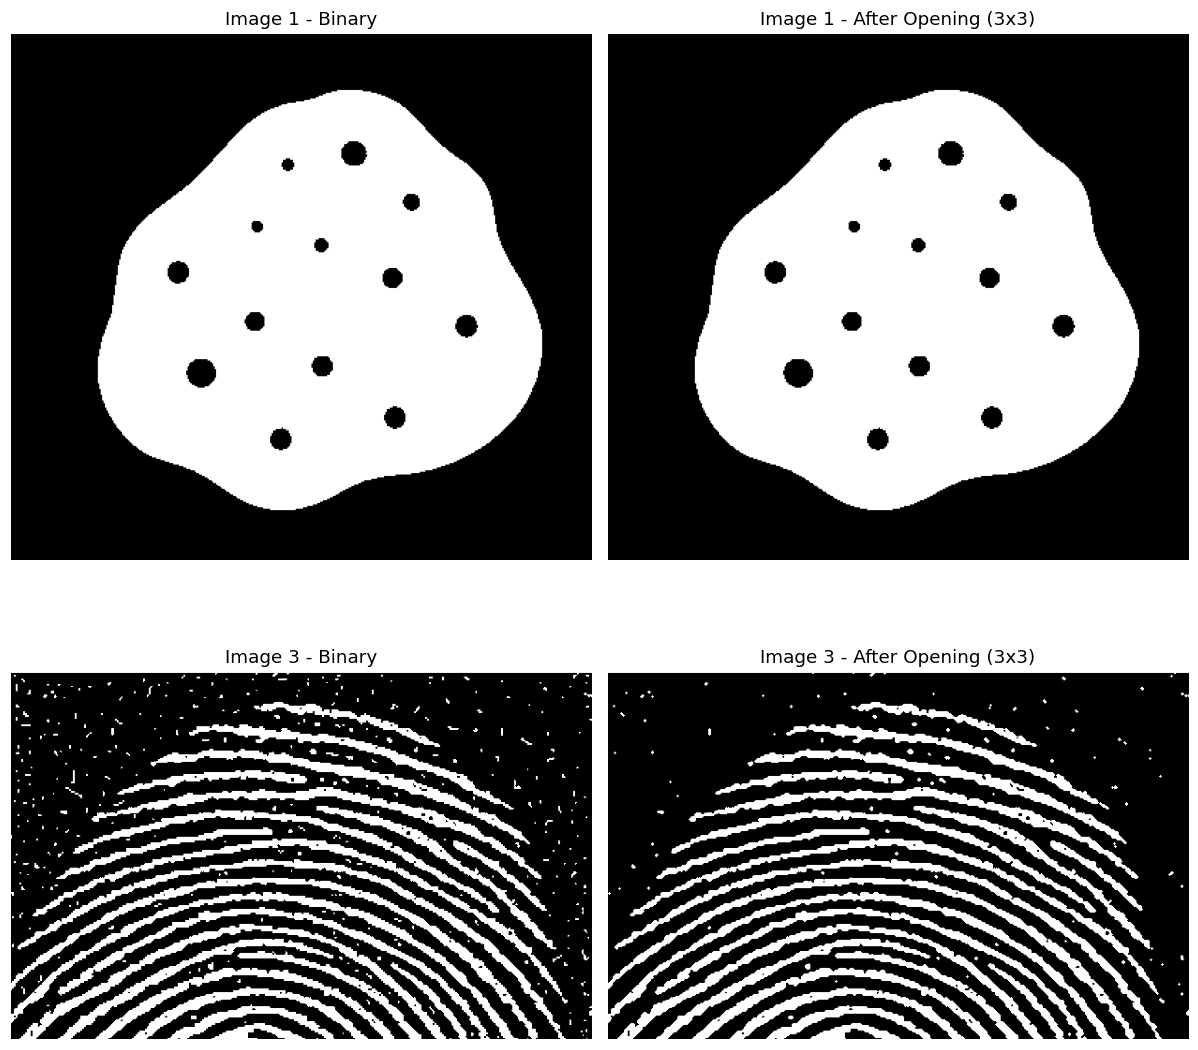

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(11, 11))
axes[0,0].imshow(bin1,  cmap="gray"); axes[0,0].set_title("Image 1 - Binary")
axes[0,1].imshow(open1, cmap="gray"); axes[0,1].set_title("Image 1 - After Opening (3x3)")
axes[1,0].imshow(bin3,  cmap="gray"); axes[1,0].set_title("Image 3 - Binary")
axes[1,1].imshow(open3, cmap="gray"); axes[1,1].set_title("Image 3 - After Opening (3x3)")
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 11. Apply Morphological Closing
Closing = dilation followed by erosion: **A • B = (A ⊕ B) ⊖ B**. It fills narrow dark cracks and small holes inside the foreground.
The closing is applied to the **opened** image, so the order of operations is **Opening → Closing**.

In [15]:
final1 = cv2.morphologyEx(open1, cv2.MORPH_CLOSE, k5)  # Image 1 : fill holes / cracks (5x5)
final3 = cv2.morphologyEx(open3, cv2.MORPH_CLOSE, k3)  # Image 3 : fill narrow gaps in ridges (3x3)

# closing applied alone (for comparison of the order of operations)
close1_only = cv2.morphologyEx(bin1, cv2.MORPH_CLOSE, k5)
close3_only = cv2.morphologyEx(bin3, cv2.MORPH_CLOSE, k3)

## 12. Display Closing Results

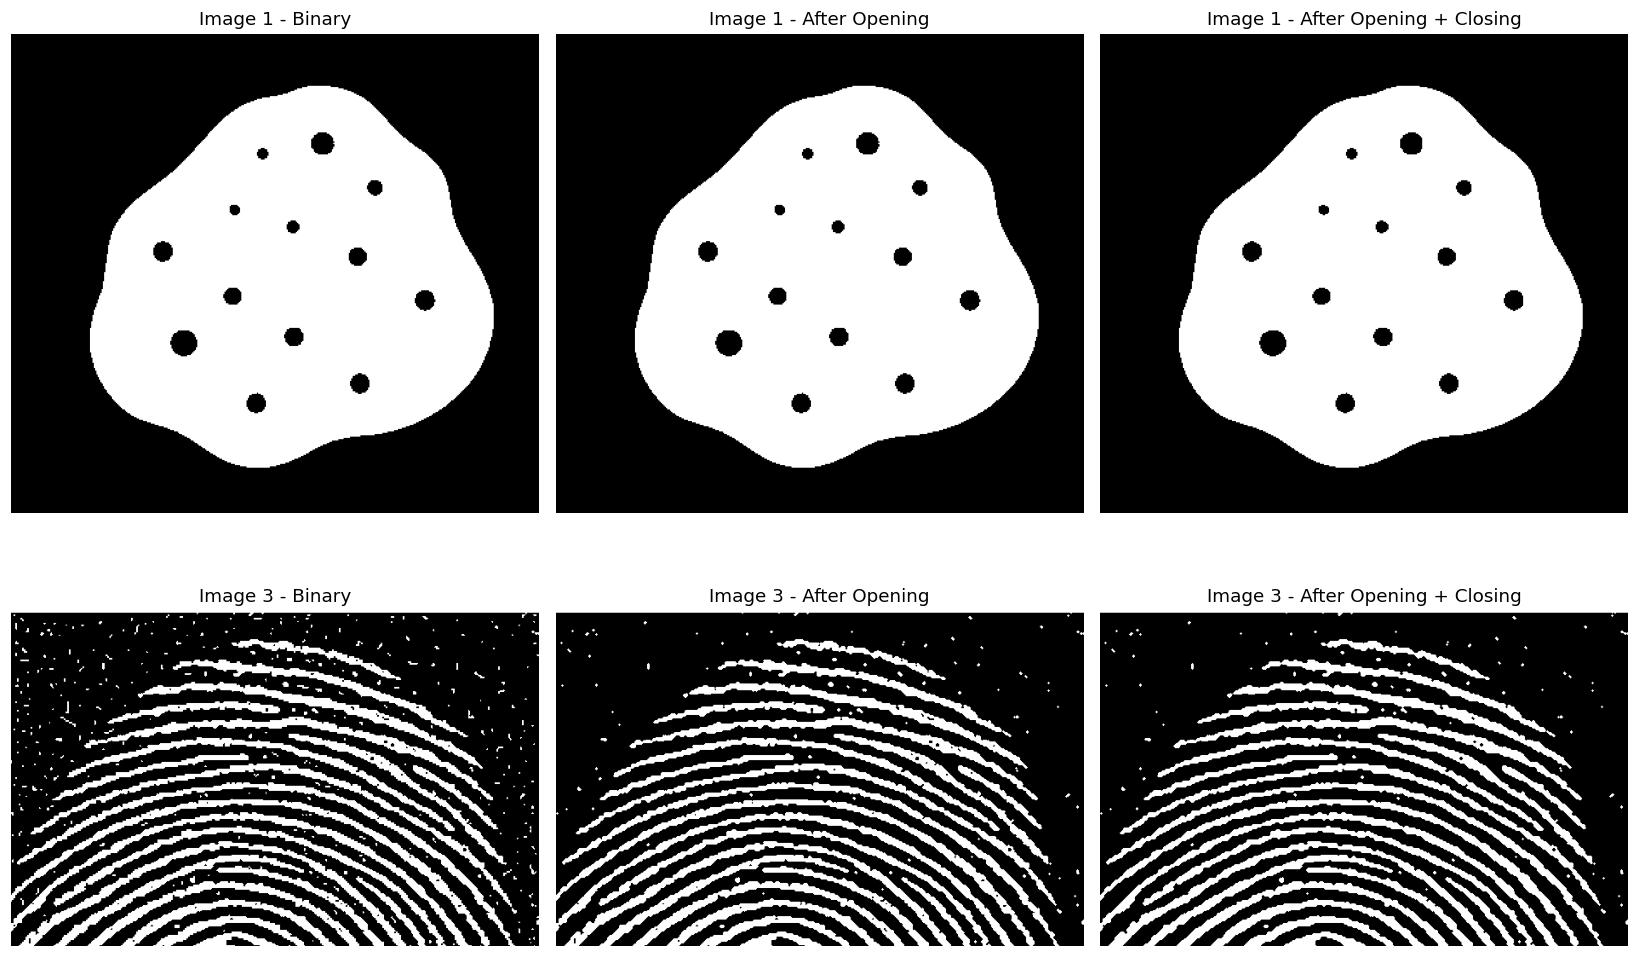

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
rows = [("Image 1", bin1, open1, final1), ("Image 3", bin3, open3, final3)]
for r, (name, b, o, f) in enumerate(rows):
    for c, (im, t) in enumerate(zip([b, o, f], ["Binary", "After Opening", "After Opening + Closing"])):
        axes[r, c].imshow(im, cmap="gray"); axes[r, c].set_title(f"{name} - {t}"); axes[r, c].axis("off")
plt.tight_layout(); plt.show()

## 13. Apply Morphological Operations to the Grayscale Photograph
Image 2 is an old photograph, so **grayscale morphology** is used:

* **White Top-Hat** `TW(f) = f − (f ∘ B)` → extracts small *bright* details (dust, specks).
* **Black-Hat** `TB(f) = (f • B) − f` → extracts small *dark* details (thin cracks, scratches).

Processed photograph = `f − TW + TB` (bright specks are subtracted, dark scratches are added back).

In [17]:
k_photo = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

tophat   = cv2.morphologyEx(g2, cv2.MORPH_TOPHAT,   k_photo)   # bright details
blackhat = cv2.morphologyEx(g2, cv2.MORPH_BLACKHAT, k_photo)   # dark details

no_bright = cv2.subtract(g2, tophat)            # remove small bright specks
photo_out = cv2.add(no_bright, blackhat)        # fill / lighten thin dark scratches

# Alternative (direct) approach : grayscale opening then closing
photo_oc = cv2.morphologyEx(cv2.morphologyEx(g2, cv2.MORPH_OPEN, k_photo), cv2.MORPH_CLOSE, k_photo)

## 14. Display Photograph Processing Results

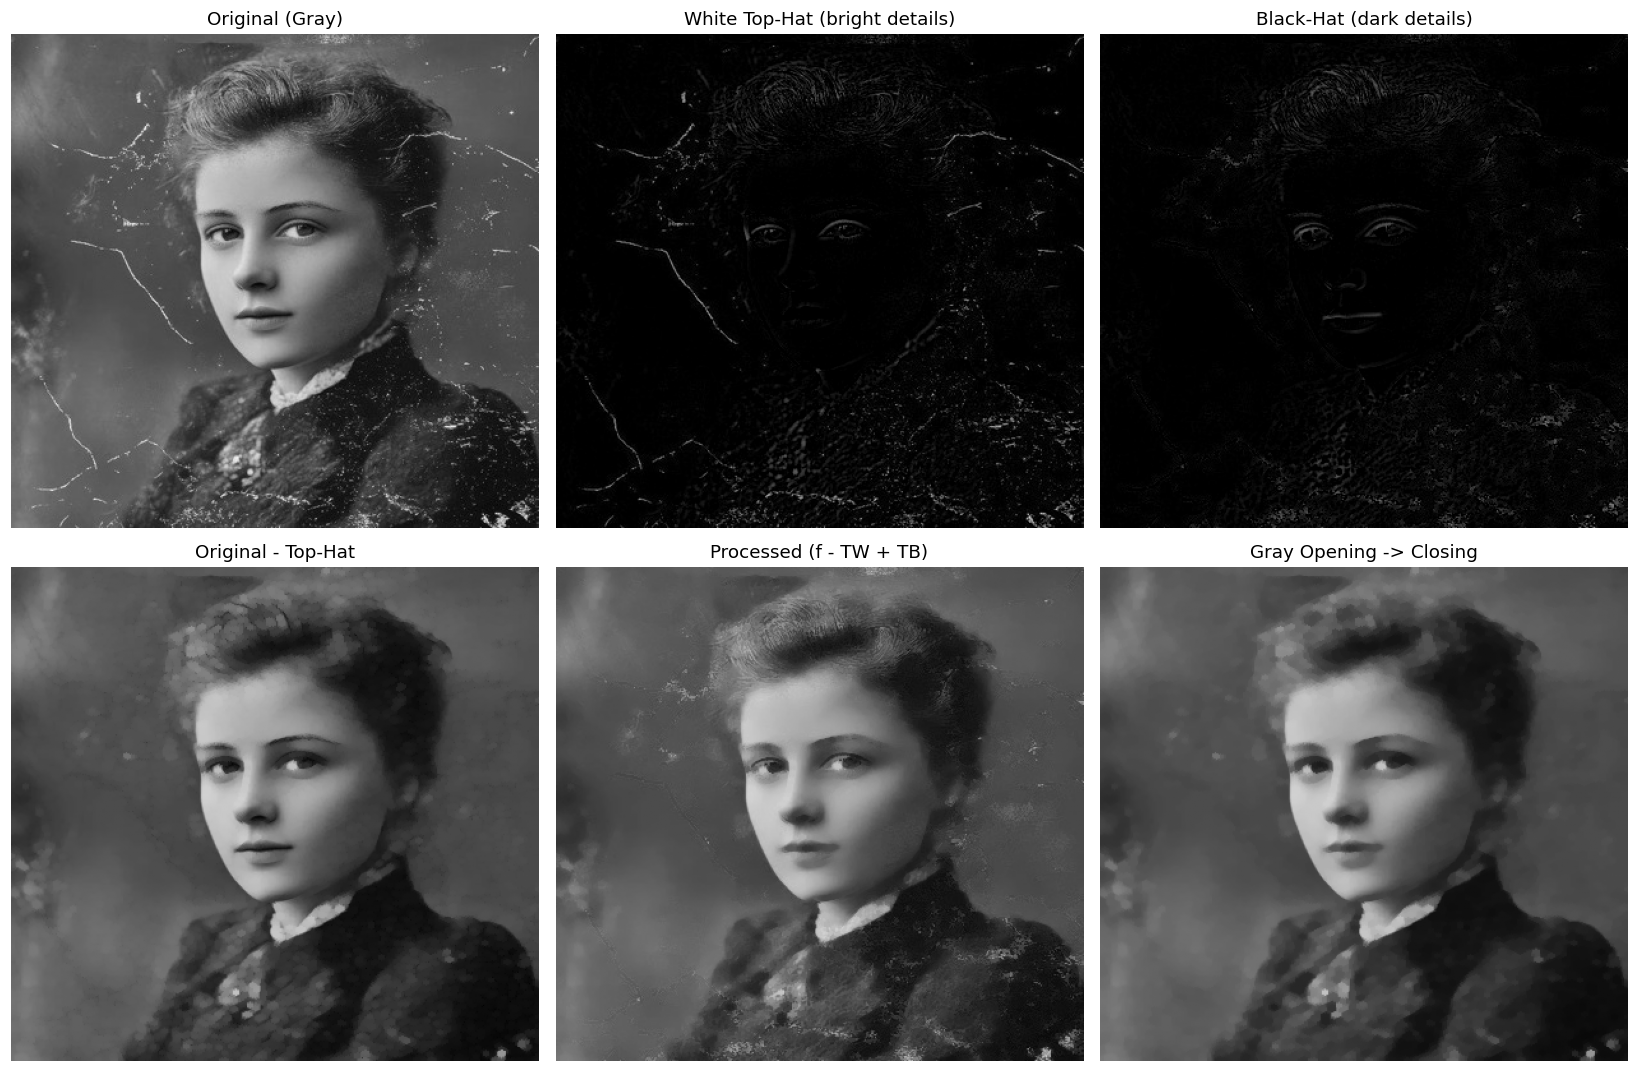

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
items = [(g2, "Original (Gray)"), (tophat, "White Top-Hat (bright details)"), (blackhat, "Black-Hat (dark details)"),
         (no_bright, "Original - Top-Hat"), (photo_out, "Processed (f - TW + TB)"), (photo_oc, "Gray Opening -> Closing")]
for ax, (im, t) in zip(axes.ravel(), items):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()

## 15. Effect of Kernel Size (Experiment)
Smaller kernels remove smaller noise and keep fine details; larger kernels remove larger noise but may destroy object boundaries.
The same Opening → Closing sequence is applied to Image 1 with kernel sizes 3, 5, 9 and 15.

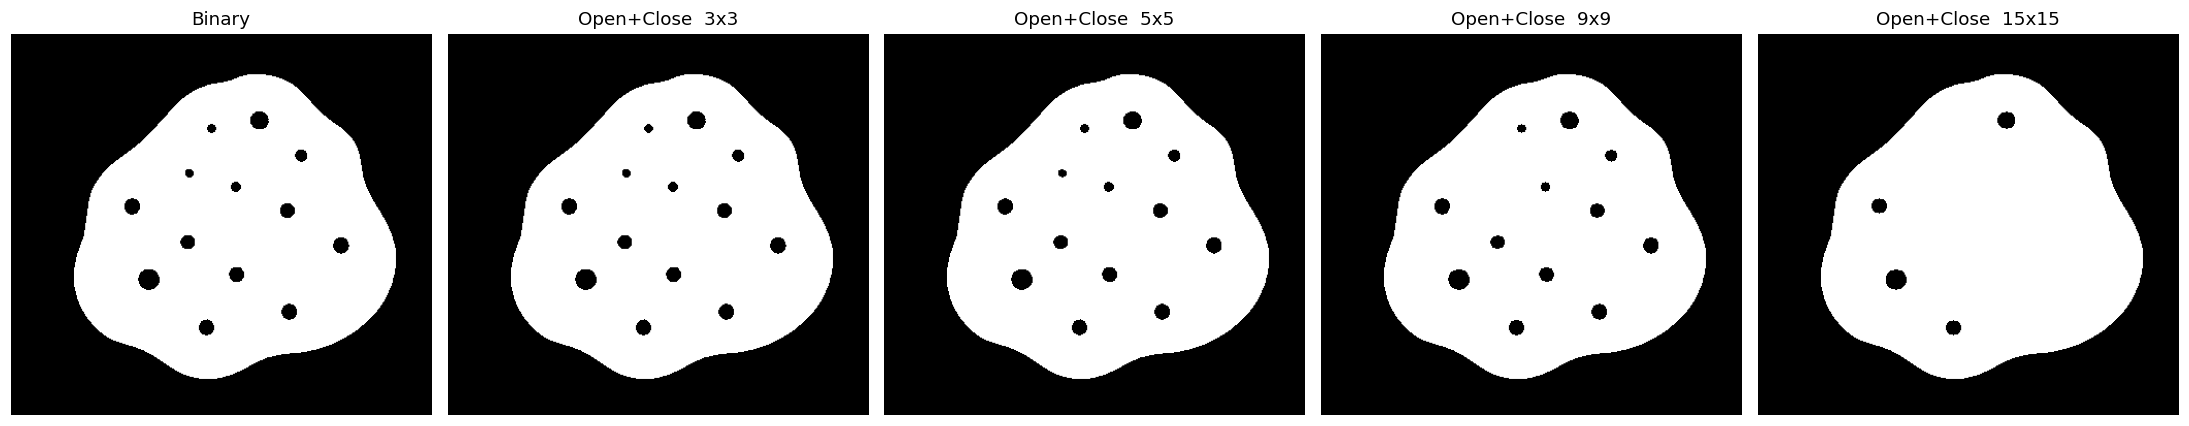

In [19]:
sizes = [3, 5, 9, 15]
fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))
axes[0].imshow(bin1, cmap="gray"); axes[0].set_title("Binary"); axes[0].axis("off")
for ax, s in zip(axes[1:], sizes):
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (s, s))
    out = cv2.morphologyEx(cv2.morphologyEx(bin1, cv2.MORPH_OPEN, k), cv2.MORPH_CLOSE, k)
    ax.imshow(out, cmap="gray"); ax.set_title(f"Open+Close  {s}x{s}"); ax.axis("off")
plt.tight_layout(); plt.show()

## 16. Effect of Structuring-Element Shape (Experiment)
Ellipse, square and cross structuring elements of the same 5×5 size are compared on Image 3.

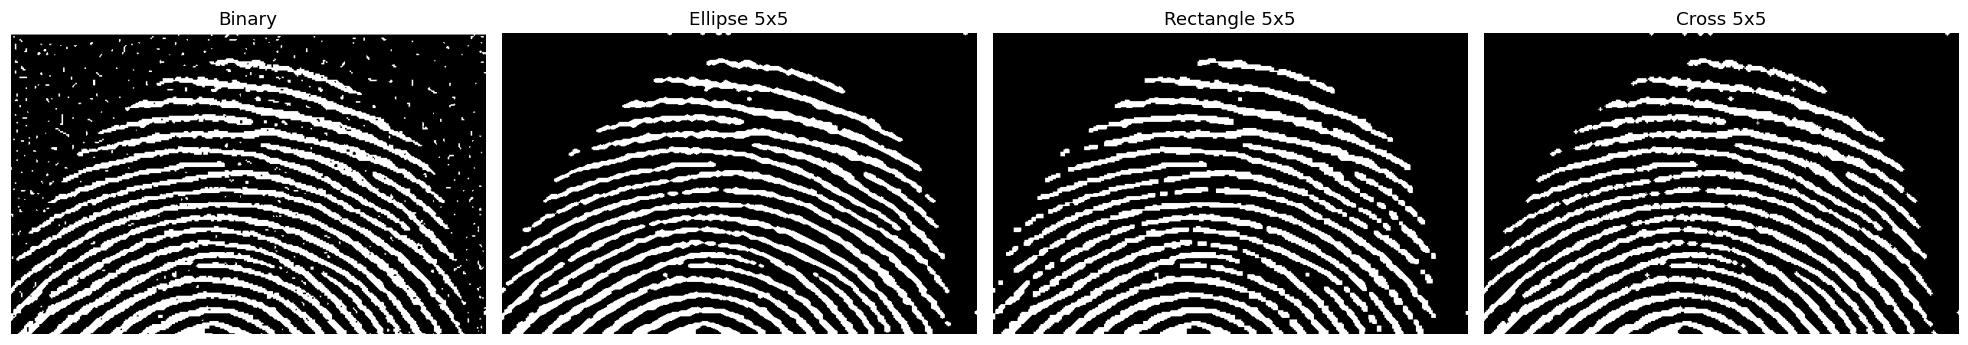

In [20]:
shapes = {"Ellipse": cv2.MORPH_ELLIPSE, "Rectangle": cv2.MORPH_RECT, "Cross": cv2.MORPH_CROSS}
fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
axes[0].imshow(bin3, cmap="gray"); axes[0].set_title("Binary"); axes[0].axis("off")
for ax, (name, shp) in zip(axes[1:], shapes.items()):
    k = cv2.getStructuringElement(shp, (5, 5))
    out = cv2.morphologyEx(cv2.morphologyEx(bin3, cv2.MORPH_OPEN, k), cv2.MORPH_CLOSE, k)
    ax.imshow(out, cmap="gray"); ax.set_title(f"{name} 5x5"); ax.axis("off")
plt.tight_layout(); plt.show()

## 17. Order of Operations: Opening→Closing vs Closing→Opening

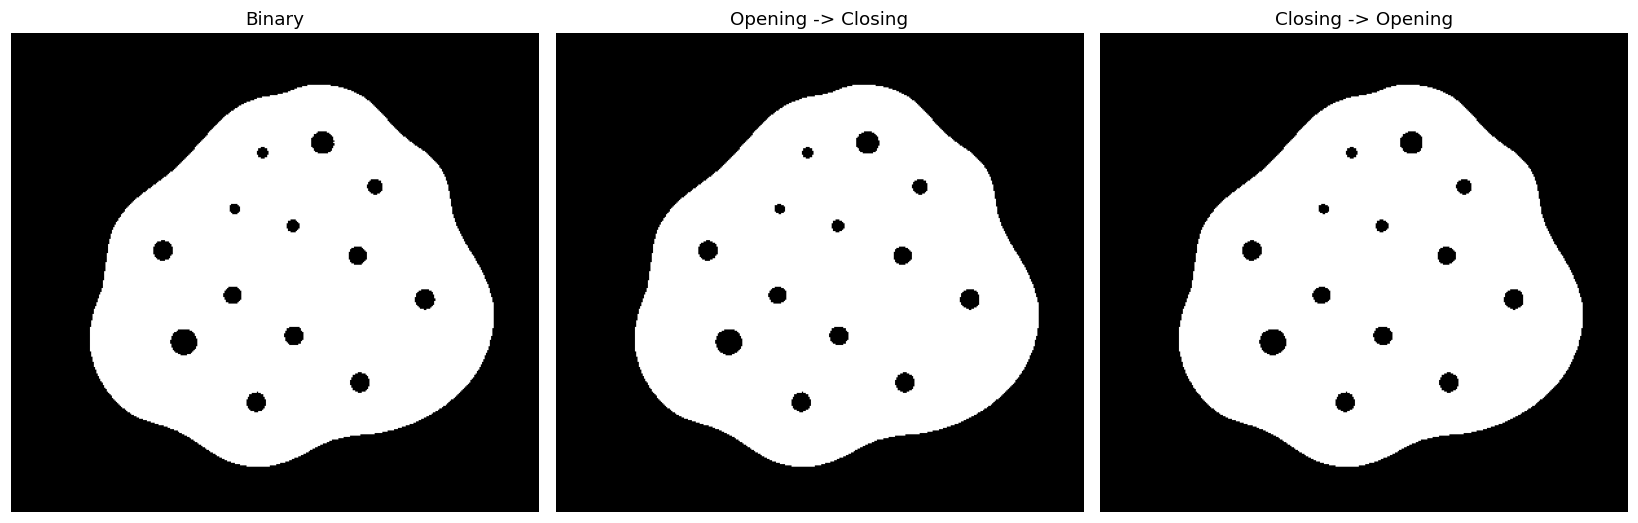

Pixels that differ between the two orders: 4


In [21]:
oc1 = cv2.morphologyEx(cv2.morphologyEx(bin1, cv2.MORPH_OPEN,  k5), cv2.MORPH_CLOSE, k5)
co1 = cv2.morphologyEx(cv2.morphologyEx(bin1, cv2.MORPH_CLOSE, k5), cv2.MORPH_OPEN,  k5)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, im, t in zip(axes, [bin1, oc1, co1], ["Binary", "Opening -> Closing", "Closing -> Opening"]):
    ax.imshow(im, cmap="gray"); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()
print("Pixels that differ between the two orders:", int(np.sum(oc1 != co1)))

## 18. Quantitative Evaluation
Noise removal and shape preservation are measured with simple numerical metrics:

* **Connected components** – number of separate white regions (noise specks create many small components).
* **Holes** – number of black regions enclosed inside the foreground.
* **Foreground area** – count of white pixels.
* **IoU with the input binary image** – overlap between each processed stage and the thresholded input (shape preservation, 1.0 = identical).
* **PSNR / mean change** for the photograph.

In [22]:
def n_components(b):
    n, _ = cv2.connectedComponents(b, connectivity=8)
    return n - 1

def n_holes(b):
    inv = cv2.bitwise_not(b)
    n, lab = cv2.connectedComponents(inv, connectivity=4)
    border = set(np.unique(np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]])))
    return len([i for i in range(1, n) if i not in border])

def largest_component(b):
    n, lab, stats, _ = cv2.connectedComponentsWithStats(b, connectivity=8)
    if n <= 1: return b.copy()
    idx = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    return np.where(lab == idx, 255, 0).astype(np.uint8)

def iou(a, b):
    a, b = a > 0, b > 0
    return (a & b).sum() / max((a | b).sum(), 1)

def psnr(a, b):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255 ** 2 / mse)

print(f"{'Image / Stage':32s}{'Components':>11s}{'Holes':>8s}{'FG pixels':>11s}{'IoU(input)':>11s}")
print("-" * 73)
for name, stages, ref in [("Image 1", [("Binary", bin1), ("Opening", open1), ("Open+Close", final1)], bin1),
                          ("Image 3", [("Binary", bin3), ("Opening", open3), ("Open+Close", final3)], bin3)]:
    for st, im in stages:
        print(f"{name + ' - ' + st:32s}{n_components(im):>11d}{n_holes(im):>8d}{int((im>0).sum()):>11d}{iou(im, ref):>11.4f}")
    print()

print("Image 2 (photograph)")
print(f"  Bright pixels > 240 : original = {(g2>240).sum():5d} | processed = {(photo_out>240).sum():5d}")
print(f"  Mean intensity      : original = {g2.mean():6.2f} | processed = {photo_out.mean():6.2f}")
print(f"  PSNR(original, processed) = {psnr(g2, photo_out):.2f} dB")

Image / Stage                    Components   Holes  FG pixels IoU(input)
-------------------------------------------------------------------------
Image 1 - Binary                          1      13      64263     1.0000
Image 1 - Opening                         1      13      64263     1.0000
Image 1 - Open+Close                      1      13      64295     0.9995

Image 3 - Binary                        370      63      65085     1.0000
Image 3 - Opening                       110      43      61496     0.9449
Image 3 - Open+Close                    107       5      61961     0.9384

Image 2 (photograph)
  Bright pixels > 240 : original =     0 | processed =     0
  Mean intensity      : original =  83.42 | processed =  82.42
  PSNR(original, processed) = 24.09 dB


## 19. Compare Original and Processed Images
Side-by-side comparison is used to evaluate the removal of bright noise, the filling of dark cracks and the preservation of the overall shape.

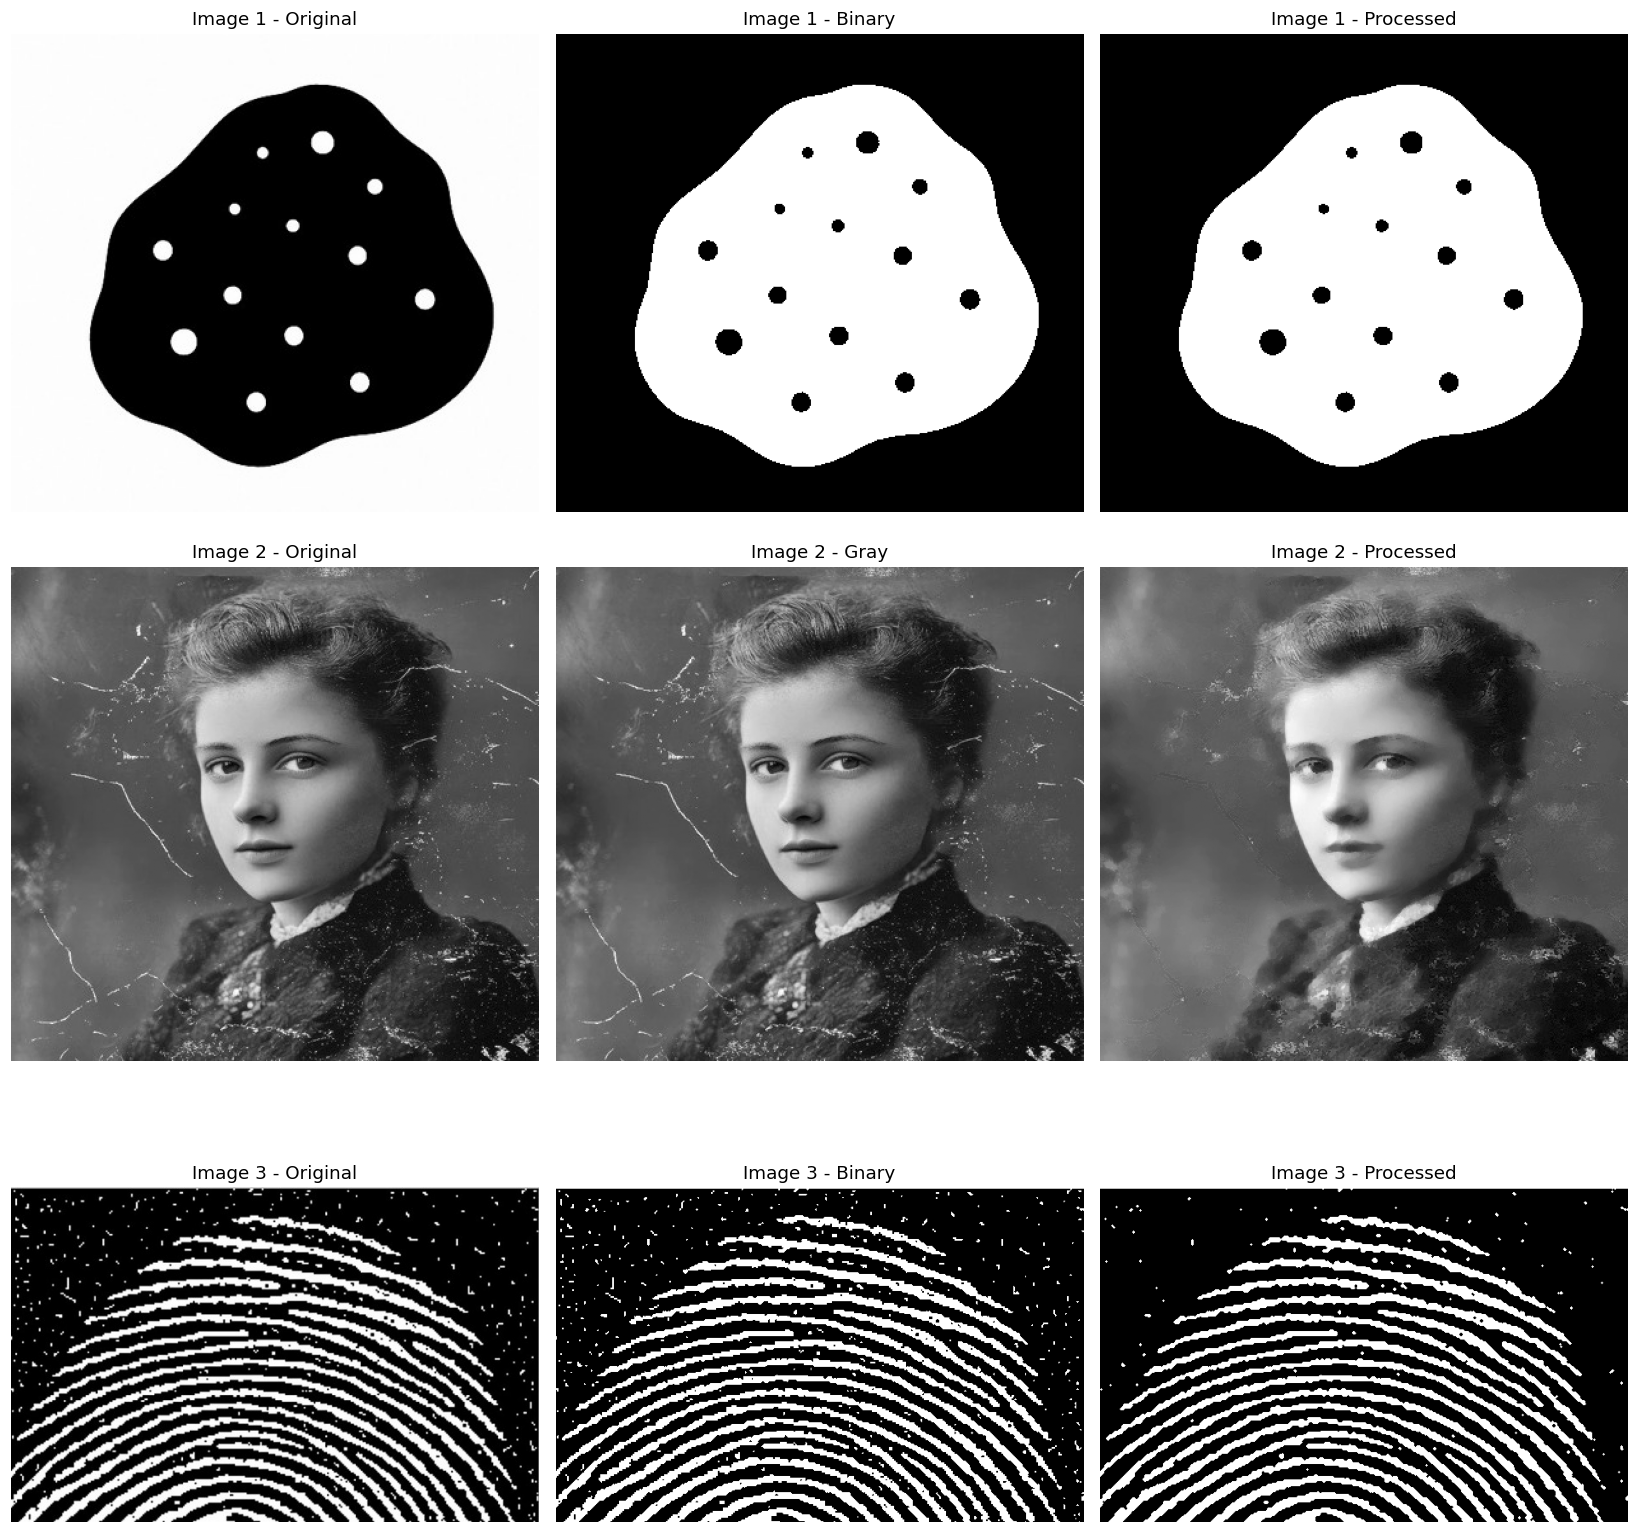

In [23]:
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
rows = [
    ("Image 1", cv2.cvtColor(images["Image 1 - Binary Object"], cv2.COLOR_BGR2RGB), bin1, final1),
    ("Image 2", g2, g2, photo_out),
    ("Image 3", cv2.cvtColor(images["Image 3 - Fingerprint"], cv2.COLOR_BGR2RGB), bin3, final3),
]
for r, (name, orig, mid, out) in enumerate(rows):
    axes[r, 0].imshow(orig, cmap="gray");        axes[r, 0].set_title(f"{name} - Original")
    axes[r, 1].imshow(mid,  cmap="gray");        axes[r, 1].set_title(f"{name} - " + ("Gray" if name == "Image 2" else "Binary"))
    axes[r, 2].imshow(out,  cmap="gray");        axes[r, 2].set_title(f"{name} - Processed")
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

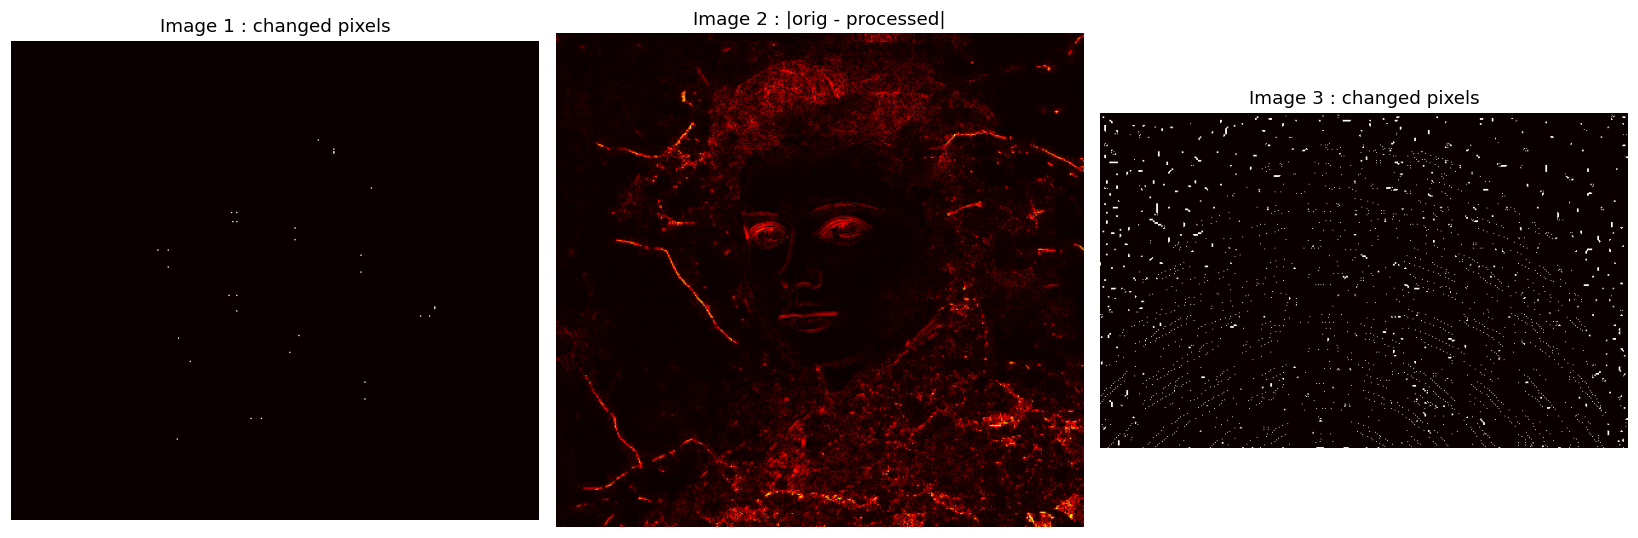

Changed pixels  Image 1 = 32 | Image 3 = 4038


In [24]:
# Difference maps : which pixels were changed by the processing?
diff1 = cv2.absdiff(bin1, final1)
diff3 = cv2.absdiff(bin3, final3)
diff2 = cv2.absdiff(g2, photo_out)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, d, t in zip(axes, [diff1, diff2, diff3], ["Image 1 : changed pixels", "Image 2 : |orig - processed|", "Image 3 : changed pixels"]):
    ax.imshow(d, cmap="hot"); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()
print("Changed pixels  Image 1 =", int((diff1 > 0).sum()), "| Image 3 =", int((diff3 > 0).sum()))

## 20. Save Processed Images
The processed images are saved in the separate folder `output/` for further analysis and inclusion in the experiment report.

In [25]:
results = {
    "image1_binary.png": bin1,      "image1_opening.png": open1,   "image1_final.png": final1,
    "image2_gray.png": g2,          "image2_tophat.png": tophat,   "image2_blackhat.png": blackhat,
    "image2_final.png": photo_out,
    "image3_binary.png": bin3,      "image3_opening.png": open3,   "image3_final.png": final3,
}
for name, im in results.items():
    cv2.imwrite(os.path.join(OUTPUT_DIR, name), im)
print("Saved files:", sorted(os.listdir(OUTPUT_DIR)))

Saved files: ['background_only.mp3', 'image1_Adaptive_median.png', 'image1_Alpha-trimmed_5x5.png', 'image1_Mean_3x3.png', 'image1_Morph_open-close_3x3.png', 'image1_Switching_median_3x3.png', 'image1_best.png', 'image1_binary.png', 'image1_final.png', 'image1_median_3x3.png', 'image1_median_5x5.png', 'image1_median_7x7.png', 'image1_median_9x9.png', 'image1_opening.png', 'image2_Adaptive_median.png', 'image2_Alpha-trimmed_5x5.png', 'image2_Mean_3x3.png', 'image2_Morph_open-close_3x3.png', 'image2_Switching_median_5x5.png', 'image2_best.png', 'image2_blackhat.png', 'image2_final.png', 'image2_gray.png', 'image2_median_3x3.png', 'image2_median_5x5.png', 'image2_median_7x7.png', 'image2_median_9x9.png', 'image2_tophat.png', 'image3_best.png', 'image3_binary.png', 'image3_final.png', 'image3_opening.png', 'image4_best.png', 'lowpass_2000Hz.mp3', 'lowpass_5000Hz.mp3', 'lowpass_500Hz.mp3', 'vocals_only_bandpass.mp3']


## 21. Observations, Result and Conclusion

| Image | Operations | Observation |
|---|---|---|
| Image 1 | Opening (3×3) + Closing (5×5) | Small foreground noise is removed and small holes in the main object are filled. |
| Image 2 | White Top-Hat + Black-Hat (5×5) | Small bright spots are reduced and dark scratches become less visible. |
| Image 3 | Opening (3×3) + Closing (3×3) | Isolated bright specks are removed and narrow dark gaps between fingerprint ridges are filled. |

**Choice of structuring element:** 3×3 elliptical for small specks, 5×5 elliptical for slightly larger gaps; the ellipse gives smooth boundary handling.  
**Order of operations:** Opening → Closing – first remove bright noise, then fill dark cracks and holes.

**Result:** Opening, closing, white top-hat and black-hat were applied to the three images; bright noise was reduced and narrow dark gaps were filled while the main shapes were preserved.

**Conclusion:** Morphological opening removes small foreground noise, closing fills small holes and cracks, and top-hat / black-hat transforms handle bright and dark details in grayscale photographs.
Suitable kernel size and operation order are essential to preserve object shape.